In [1]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

print("正在读取 Kaggle 信贷数据集...")

# 1. 读取数据
df = pd.read_csv('cs-training.csv')

# 2. 删除多余的索引列
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

# 3. 定义目标变量
target = 'SeriousDlqin2yrs'

# 4. 检查数据基本情况
print("\n=== 数据基本信息 ===")
print("数据集形状：", df.shape)

print("\n缺失值统计：")
print(df.isnull().sum())

print("\n目标变量分布：")
print(df[target].value_counts())

# 5. 分离特征和目标变量
X = df.drop(columns=[target])
y = df[target]

# 6. 划分训练集和测试集
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

# 7. 查看划分结果
print("\n=== 数据集划分结果 ===")
print("训练集样本量：", len(X_train))
print("测试集样本量：", len(X_test))

print("\n训练集违约率：", round(y_train.mean(), 4))
print("测试集违约率：", round(y_test.mean(), 4))

print("\n数据集划分完成！")


正在读取 Kaggle 信贷数据集...

=== 数据基本信息 ===
数据集形状： (150000, 11)

缺失值统计：
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                                   0
MonthlyIncome                           29731
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3924
dtype: int64

目标变量分布：
SeriousDlqin2yrs
0    139974
1     10026
Name: count, dtype: int64

=== 数据集划分结果 ===
训练集样本量： 105000
测试集样本量： 45000

训练集违约率： 0.0668
测试集违约率： 0.0668

数据集划分完成！


In [2]:

print("正在进行缺失值处理...")

# 1. 复制数据，避免影响原始数据
X_train = X_train.copy()
X_test = X_test.copy()

# 2. 计算训练集各特征的中位数
train_medians = X_train.median()

# 3. 使用训练集的中位数填充训练集
X_train = X_train.fillna(train_medians)

# 4. 使用相同的中位数填充测试集
X_test = X_test.fillna(train_medians)

# 5. 查看重点特征的填充值
print("\n=== 缺失值填充规则 ===")
print(train_medians[['MonthlyIncome', 'NumberOfDependents']])

# 6. 检查训练集缺失值
print("\n=== 训练集缺失值检查 ===")
print(X_train.isnull().sum())

# 7. 检查测试集缺失值
print("\n=== 测试集缺失值检查 ===")
print(X_test.isnull().sum())

# 8. 检查是否全部处理完成
print("\n训练集剩余缺失值：", X_train.isnull().sum().sum())
print("测试集剩余缺失值：", X_test.isnull().sum().sum())

print("\n缺失值处理完成！")


正在进行缺失值处理...

=== 缺失值填充规则 ===
MonthlyIncome         5382.0
NumberOfDependents       0.0
dtype: float64

=== 训练集缺失值检查 ===
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: int64

=== 测试集缺失值检查 ===
RevolvingUtilizationOfUnsecuredLines    0
age                                     0
NumberOfTime30-59DaysPastDueNotWorse    0
DebtRatio                               0
MonthlyIncome                           0
NumberOfOpenCreditLinesAndLoans         0
NumberOfTimes90DaysLate                 0
NumberRealEstateLoansOrLines            0
NumberOfTime60-89DaysPastDueNotWorse    0
NumberOfDependents                      0
dtype: i

In [4]:

import toad

print("正在进行卡方分箱...")

# 1. 创建分箱器
combiner = toad.transform.Combiner()

# 2. 使用训练集拟合分箱规则
train_data = X_train.copy()
train_data[target] = y_train

combiner.fit(
    train_data,
    y=target,
    method='chi',
    n_bins=5
)

# 3. 将训练集转换成分箱数据
train_binned = combiner.transform(train_data)

# 4. 将相同的分箱规则应用于测试集
test_binned = combiner.transform(X_test)

# 5. 查看分箱结果
print("\n=== 年龄特征分箱规则 ===")
print(combiner.export()['age'])

print("\n=== 训练集分箱结果 ===")
print(train_binned['age'].value_counts().sort_index())

print("\n=== 测试集分箱结果 ===")
print(test_binned['age'].value_counts().sort_index())

print("\n卡方分箱完成！")
print("=== 所有特征的分箱规则 ===")

for feature, bins in combiner.export().items():
    print(f"{feature}: {bins}")

正在进行卡方分箱...

=== 年龄特征分箱规则 ===
[37, 44, 54, 63]

=== 训练集分箱结果 ===
age
0    16671
1    14494
2    25536
3    21811
4    26488
Name: count, dtype: int64

=== 测试集分箱结果 ===
age
0     7194
1     6150
2    10973
3     9201
4    11482
Name: count, dtype: int64

卡方分箱完成！
=== 所有特征的分箱规则 ===
RevolvingUtilizationOfUnsecuredLines: [0.085343391, 0.302078573, 0.667844405, 1.0]
age: [37, 44, 54, 63]
NumberOfTime30-59DaysPastDueNotWorse: [1, 2, 3, 4]
DebtRatio: [0.076866667, 0.354411397, 0.50950794, 1.991519896]
MonthlyIncome: [1164.0, 3034.0, 5382.0, 6525.0]
NumberOfOpenCreditLinesAndLoans: [2, 4, 6, 14]
NumberOfTimes90DaysLate: [1, 2, 3, 4]
NumberRealEstateLoansOrLines: [1, 2, 3, 5]
NumberOfTime60-89DaysPastDueNotWorse: [1, 2, 3, 7]
NumberOfDependents: [1.0, 2.0, 3.0, 4.0]


In [5]:

import toad

print("正在计算各特征的 IV 值...")

# 1. 使用训练集的分箱数据计算 IV
iv_table = toad.quality(
    train_binned,
    target=target,
    iv_only=True
)

# 2. 按照 IV 值从高到低排序
iv_table = iv_table.sort_values(
    by='iv',
    ascending=False
)

# 3. 输出 IV 结果
print("\n=== 各特征 IV 值 ===")
print(iv_table)

from toad.transform import WOETransformer

print("正在进行 WOE 编码...")

# 1. 创建 WOE 编码器
woe_transformer = WOETransformer()

# 2. 训练集拟合并转换
X_train_binned = train_binned.drop(columns=[target])

X_train_woe = woe_transformer.fit_transform(
    X_train_binned,
    y_train
)

# 3. 测试集使用训练集学习到的编码规则
X_test_woe = woe_transformer.transform(
    test_binned
)

# 4. 查看 WOE 编码结果
print("\n=== 训练集 WOE 编码结果 ===")
print(X_train_woe.head())

print("\n=== 测试集 WOE 编码结果 ===")
print(X_test_woe.head())

print("\nWOE 编码完成！")

print("正在进行 IV 特征筛选...")

# 1. 设置 IV 筛选阈值
iv_threshold = 0.02

# 2. 筛选 IV 大于等于阈值的特征
selected_features = iv_table[
    iv_table['iv'] >= iv_threshold
].index.tolist()

# 3. 输出筛选结果
print("\n=== 特征筛选结果 ===")

print("原始特征数量：", len(X_train_woe.columns))
print("筛选后特征数量：", len(selected_features))

print("\n保留的特征：")
for feature in selected_features:
    print(feature, "IV =", round(iv_table.loc[feature, 'iv'], 4))

# 4. 得到最终建模数据
X_train_final = X_train_woe[selected_features]
X_test_final = X_test_woe[selected_features]

print("\n最终训练集形状：", X_train_final.shape)
print("最终测试集形状：", X_test_final.shape)

print("\nWOE 编码与 IV 特征筛选完成！")


正在计算各特征的 IV 值...

=== 各特征 IV 值 ===
                                            iv  gini  entropy  unique
RevolvingUtilizationOfUnsecuredLines  1.115185   NaN      NaN     5.0
NumberOfTimes90DaysLate               0.892961   NaN      NaN     5.0
NumberOfTime30-59DaysPastDueNotWorse  0.741532   NaN      NaN     5.0
NumberOfTime60-89DaysPastDueNotWorse  0.602782   NaN      NaN     5.0
age                                   0.234674   NaN      NaN     5.0
NumberOfOpenCreditLinesAndLoans       0.096706   NaN      NaN     5.0
MonthlyIncome                         0.078659   NaN      NaN     5.0
DebtRatio                             0.071615   NaN      NaN     5.0
NumberRealEstateLoansOrLines          0.064877   NaN      NaN     5.0
NumberOfDependents                    0.032894   NaN      NaN     5.0
正在进行 WOE 编码...

=== 训练集 WOE 编码结果 ===
        RevolvingUtilizationOfUnsecuredLines       age  \
138985                             -1.343879  0.161116   
63964                              -1.3438

In [6]:

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve
import numpy as np
import pandas as pd

print("正在训练逻辑回归模型...")

# 1. 创建逻辑回归模型
lr = LogisticRegression(
    max_iter=2000,
    solver='lbfgs'
)

# 2. 使用训练集训练模型
lr.fit(X_train_final, y_train)

# 3. 预测测试集违约概率
y_pred_proba = lr.predict_proba(X_test_final)[:, 1]

# 4. 计算 AUC
auc = roc_auc_score(y_test, y_pred_proba)

print("\n=== 模型训练结果 ===")
print("模型训练完成！")
print(f"AUC值：{auc:.4f}")

# 5. 计算 KS
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_pred_proba
)

ks = max(tpr - fpr)

print(f"KS值：{ks:.4f}")

# 6. 查看模型系数
coef_table = pd.DataFrame({
    '特征': X_train_final.columns,
    '回归系数': lr.coef_[0]
})

coef_table['系数绝对值'] = coef_table['回归系数'].abs()

coef_table = coef_table.sort_values(
    by='系数绝对值',
    ascending=False
)

print("\n=== 模型特征系数 ===")
print(coef_table)

print("\n模型评估完成！")


正在训练逻辑回归模型...

=== 模型训练结果 ===
模型训练完成！
AUC值：0.8568
KS值：0.5617

=== 模型特征系数 ===
                                     特征      回归系数     系数绝对值
7                             DebtRatio  0.862539  0.862539
8          NumberRealEstateLoansOrLines  0.665190  0.665190
0  RevolvingUtilizationOfUnsecuredLines  0.599325  0.599325
1               NumberOfTimes90DaysLate  0.530216  0.530216
2  NumberOfTime30-59DaysPastDueNotWorse  0.494229  0.494229
4                                   age  0.391463  0.391463
3  NumberOfTime60-89DaysPastDueNotWorse  0.374787  0.374787
9                    NumberOfDependents  0.242459  0.242459
6                         MonthlyIncome  0.217445  0.217445
5       NumberOfOpenCreditLinesAndLoans  0.146881  0.146881

模型评估完成！


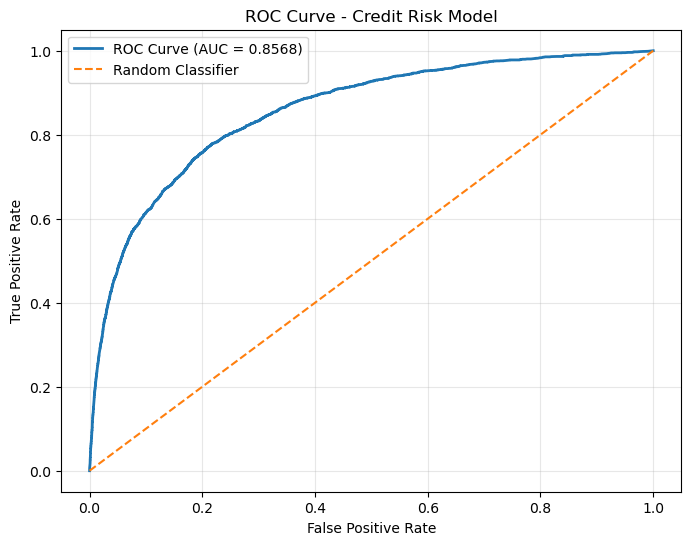

In [7]:

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

# 1. 计算 ROC 曲线
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

# 2. 绘制 ROC 曲线
plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f'ROC Curve (AUC = {roc_auc:.4f})',
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Credit Risk Model')

plt.legend()
plt.grid(alpha=0.3)
plt.show()


正在进行信用评分转换...

=== 信用评分结果示例 ===
   实际是否违约  预测违约概率    信用评分
0       1  0.1214  742.75
1       0  0.0130  912.21
2       0  0.0731  783.26
3       0  0.0206  878.59
4       1  0.0135  909.49
5       0  0.0210  877.22
6       0  0.4377  618.06
7       0  0.0300  850.64
8       0  0.0361  836.89
9       0  0.0140  906.92

=== 信用评分统计 ===
count    45000.00000
mean       839.05345
std         84.77783
min        378.06000
25%        796.61000
50%        861.62000
75%        902.33000
max        948.69000
Name: 信用评分, dtype: float64


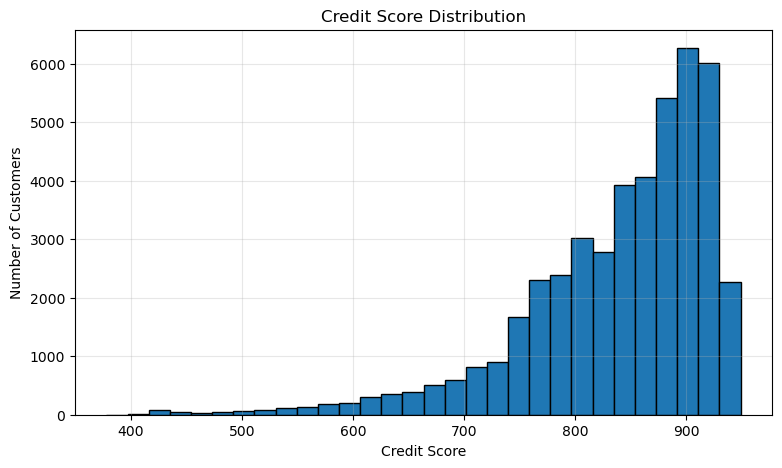

In [8]:

import numpy as np
import pandas as pd

print("正在进行信用评分转换...")

# 1. 定义信用评分转换函数
def prob_to_score(p, base=600, pdo=50):

    # 防止概率为0或1
    p = np.clip(p, 0.0001, 0.9999)

    # 计算好坏赔率
    odds = (1 - p) / p

    # 转换为信用评分
    score = base + (pdo / np.log(2)) * np.log(odds)

    return score


# 2. 获取测试集预测概率
test_proba = lr.predict_proba(X_test_final)[:, 1]

# 3. 转换为信用评分
test_scores = prob_to_score(test_proba)

# 4. 生成评分结果表
score_result = pd.DataFrame({
    '实际是否违约': y_test.values,
    '预测违约概率': test_proba,
    '信用评分': test_scores
})

# 5. 保留两位小数
score_result['预测违约概率'] = score_result['预测违约概率'].round(4)
score_result['信用评分'] = score_result['信用评分'].round(2)

# 6. 查看前10条结果
print("\n=== 信用评分结果示例 ===")
print(score_result.head(10))

# 7. 查看整体评分分布
print("\n=== 信用评分统计 ===")
print(score_result['信用评分'].describe())

plt.figure(figsize=(9, 5))

plt.hist(
    test_scores,
    bins=30,
    edgecolor='black'
)

plt.xlabel('Credit Score')
plt.ylabel('Number of Customers')
plt.title('Credit Score Distribution')

plt.grid(alpha=0.3)
plt.show()


In [9]:


# 计算训练集的预测违约概率
train_proba = lr.predict_proba(X_train_final)[:, 1]

# 将训练集违约概率转换为信用评分
train_scores = prob_to_score(train_proba)

# 测试集评分已经计算过，直接使用 test_scores

print("训练集评分统计：")
print(pd.Series(train_scores).describe())

print("\n测试集评分统计：")
print(pd.Series(test_scores).describe())

def calculate_psi(expected, actual, bins=10):
    """
    expected：基准数据
    actual：监控数据
    bins：分箱数量
    """

    expected = np.asarray(expected)
    actual = np.asarray(actual)

    # 使用基准数据的分位数确定分箱边界
    breakpoints = np.quantile(
        expected,
        np.linspace(0, 1, bins + 1)
    )

    # 去除重复边界，并扩展到无穷范围
    breakpoints = np.unique(breakpoints)
    breakpoints[0] = -np.inf
    breakpoints[-1] = np.inf

    # 按照相同边界对两组数据分箱
    expected_bins = pd.cut(
        expected, bins=breakpoints, include_lowest=True
    )
    actual_bins = pd.cut(
        actual, bins=breakpoints, include_lowest=True
    )

    # 计算每个箱的样本占比
    expected_pct = (
        pd.Series(expected_bins).value_counts(sort=False)
        / len(expected)
    )
    actual_pct = (
        pd.Series(actual_bins).value_counts(sort=False)
        / len(actual)
    )

    # 防止出现比例为0的情况
    epsilon = 1e-6
    expected_pct = expected_pct.clip(lower=epsilon)
    actual_pct = actual_pct.clip(lower=epsilon)

    # 计算PSI
    psi = np.sum(
        (actual_pct - expected_pct)
        * np.log(actual_pct / expected_pct)
    )

    return psi

score_psi = calculate_psi(
    train_scores,
    test_scores,
    bins=10
)

print("信用评分PSI：", round(score_psi, 6))

if score_psi < 0.1:
    print("模型评分分布变化较小")
elif score_psi < 0.25:
    print("模型评分分布存在一定变化")
else:
    print("模型评分分布变化较明显，需要进一步分析")


训练集评分统计：
count    105000.000000
mean        838.658962
std          85.325544
min         344.073699
25%         795.763623
50%         861.512720
75%         902.327063
max         947.810202
dtype: float64

测试集评分统计：
count    45000.000000
mean       839.053316
std         84.777721
min        378.056680
25%        796.607763
50%        861.622669
75%        902.327063
max        948.691023
dtype: float64
信用评分PSI： 0.000207
模型评分分布变化较小


=== 各特征 PSI 结果 ===
                                特征名称      PSI
                           DebtRatio 0.000322
                       MonthlyIncome 0.000261
RevolvingUtilizationOfUnsecuredLines 0.000174
     NumberOfOpenCreditLinesAndLoans 0.000156
NumberOfTime30-59DaysPastDueNotWorse 0.000129
NumberOfTime60-89DaysPastDueNotWorse 0.000108
                                 age 0.000107
             NumberOfTimes90DaysLate 0.000096
        NumberRealEstateLoansOrLines 0.000089
                  NumberOfDependents 0.000053


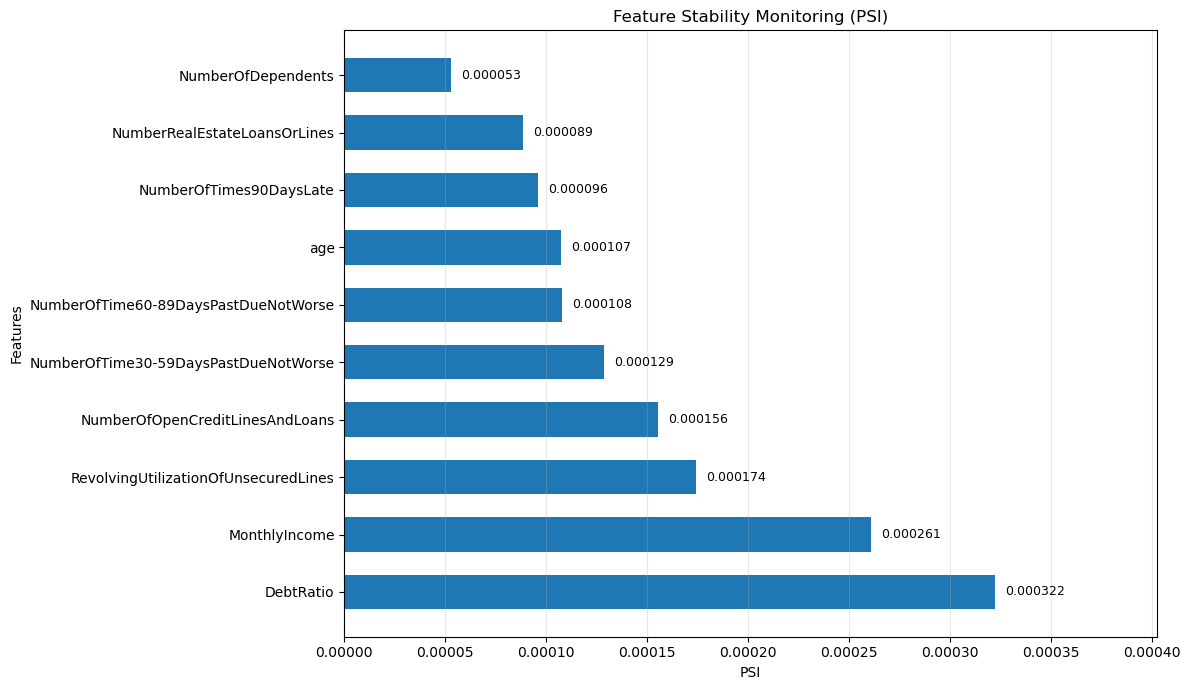

In [12]:

def calculate_psi_categorical(expected, actual):
    """
    expected：基准数据的分箱结果
    actual：监控数据的分箱结果
    """

    expected = pd.Series(expected)
    actual = pd.Series(actual)

    # 获取两组数据中出现过的所有分箱
    categories = pd.Index(
        pd.concat([expected, actual]).dropna().unique()
    )

    # 统计每个箱的样本数量
    expected_count = (
        expected.value_counts()
        .reindex(categories, fill_value=0)
    )

    actual_count = (
        actual.value_counts()
        .reindex(categories, fill_value=0)
    )

    # 加入平滑项，避免出现比例为0
    epsilon = 1e-6

    expected_pct = (
        (expected_count + epsilon)
        / (expected_count.sum() + epsilon * len(categories))
    )

    actual_pct = (
        (actual_count + epsilon)
        / (actual_count.sum() + epsilon * len(categories))
    )

    # 计算PSI
    psi = np.sum(
        (actual_pct - expected_pct)
        * np.log(actual_pct / expected_pct)
    )

    return psi

psi_results = []

for feature in X_train.columns:

    psi_value = calculate_psi_categorical(
        train_binned[feature],
        test_binned[feature]
    )

    psi_results.append({
        '特征名称': feature,
        'PSI': psi_value
    })

# 转换为DataFrame并排序
psi_table = pd.DataFrame(psi_results)

psi_table = psi_table.sort_values(
    by='PSI',
    ascending=False
)

print("=== 各特征 PSI 结果 ===")
print(psi_table.to_string(index=False))


import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))

# 绘制水平柱状图
bars = plt.barh(
    psi_table['特征名称'],
    psi_table['PSI'],
    height=0.6
)

# 在每个柱子后面标注具体数值
for bar in bars:
    width = bar.get_width()
    plt.text(
        width + 0.000005,
        bar.get_y() + bar.get_height() / 2,
        f'{width:.6f}',
        va='center',
        fontsize=9
    )

# 横坐标只展示实际PSI数据范围
plt.xlim(0, psi_table['PSI'].max() * 1.25)

plt.xlabel('PSI')
plt.ylabel('Features')
plt.title('Feature Stability Monitoring (PSI)')

plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

# PDO参数
PDO = 50

# 分数转换系数
factor = PDO / np.log(2)

# 获取逻辑回归模型截距
intercept = lr.intercept_[0]

# 计算基础分
base_score = 600 - factor * intercept

print("模型截距：", intercept)
print("分数转换系数：", factor)
print("评分卡基础分：", base_score)

# 查看每个特征的逻辑回归系数
coef_table = pd.DataFrame({
    '特征名称': X_train_final.columns,
    '模型系数': lr.coef_[0]
})

print("\n=== 模型系数 ===")
print(coef_table.to_string(index=False))


模型截距： -2.6064269268131484
分数转换系数： 72.13475204444818
评分卡基础分： 788.0139600876396

=== 模型系数 ===
                                特征名称     模型系数
RevolvingUtilizationOfUnsecuredLines 0.599325
             NumberOfTimes90DaysLate 0.530216
NumberOfTime30-59DaysPastDueNotWorse 0.494229
NumberOfTime60-89DaysPastDueNotWorse 0.374787
                                 age 0.391463
     NumberOfOpenCreditLinesAndLoans 0.146881
                       MonthlyIncome 0.217445
                           DebtRatio 0.862539
        NumberRealEstateLoansOrLines 0.665190
                  NumberOfDependents 0.242459


In [14]:

print("WOE转换器类型：")
print(type(woe_transformer))

print("\nWOE转换器内部属性：")
print(woe_transformer.__dict__.keys())

print("\nWOE转换规则：")
print(getattr(woe_transformer, 'rules', '没有找到 rules 属性'))


WOE转换器类型：
<class 'toad.transform.WOETransformer'>

WOE转换器内部属性：
dict_keys(['_rules'])

WOE转换规则：
{'RevolvingUtilizationOfUnsecuredLines': {'value': array([0, 1, 2, 3, 4]), 'woe': array([-1.34387925, -0.8840094 ,  0.0904866 ,  1.07748636,  2.10322361])}, 'age': {'value': array([0, 1, 2, 3, 4]), 'woe': array([ 0.52530182,  0.3256491 ,  0.16111629, -0.20896293, -0.92856012])}, 'NumberOfTime30-59DaysPastDueNotWorse': {'value': array([0, 1, 2, 3, 4]), 'woe': array([-0.53208095,  0.8821937 ,  1.63419734,  1.9835919 ,  2.4784695 ])}, 'DebtRatio': {'value': array([0, 1, 2, 3, 4]), 'woe': array([-0.14076331, -0.1426813 ,  0.01294018,  0.51465221, -0.21765689])}, 'MonthlyIncome': {'value': array([0, 1, 2, 3, 4]), 'woe': array([-0.18393895,  0.45127477,  0.21282529, -0.12495775, -0.32820459])}, 'NumberOfOpenCreditLinesAndLoans': {'value': array([0, 1, 2, 3, 4]), 'woe': array([ 1.04915938,  0.22707327, -0.05369053, -0.18412976,  0.03410054])}, 'NumberOfTimes90DaysLate': {'value': array([0, 1, 2, 3, 

In [15]:

# 查看卡方分箱器保存的规则
print("卡方分箱器内部属性：")
print(combiner.__dict__.keys())

print("\n卡方分箱规则：")
print(combiner._rules)


卡方分箱器内部属性：
dict_keys(['_rules'])

卡方分箱规则：
{'RevolvingUtilizationOfUnsecuredLines': array([0.08534339, 0.30207857, 0.6678444 , 1.        ]), 'age': array([37, 44, 54, 63]), 'NumberOfTime30-59DaysPastDueNotWorse': array([1, 2, 3, 4]), 'DebtRatio': array([0.07686667, 0.3544114 , 0.50950794, 1.9915199 ]), 'MonthlyIncome': array([1164., 3034., 5382., 6525.]), 'NumberOfOpenCreditLinesAndLoans': array([ 2,  4,  6, 14]), 'NumberOfTimes90DaysLate': array([1, 2, 3, 4]), 'NumberRealEstateLoansOrLines': array([1, 2, 3, 5]), 'NumberOfTime60-89DaysPastDueNotWorse': array([1, 2, 3, 7]), 'NumberOfDependents': array([1., 2., 3., 4.])}


In [16]:

# 将训练集转换为分箱区间标签
train_binned_labels = combiner.transform(
    X_train,
    labels=True
)

# 查看年龄特征的实际分箱标签
print("年龄分箱标签：")
print(train_binned_labels['age'].value_counts().sort_index())

print("\n年龄分箱标签示例：")
print(train_binned_labels['age'].head(10))

# 创建评分卡明细
scorecard_rows = []

# 获取模型特征及其对应系数
feature_names = list(X_train_final.columns)
model_coefs = dict(zip(feature_names, lr.coef_[0]))

for feature in feature_names:

    # 获取当前特征的WOE规则
    woe_rule = woe_transformer._rules[feature]

    # 获取当前特征的模型系数
    coef = model_coefs[feature]

    # 遍历每个分箱
    for bin_id, woe_value in zip(
        woe_rule['value'],
        woe_rule['woe']
    ):

        # 计算该分箱对应的分值
        points = -factor * coef * woe_value

        scorecard_rows.append({
            '特征名称': feature,
            '分箱编号': int(bin_id),
            'WOE值': woe_value,
            '模型系数': coef,
            '对应分值': points
        })

# 转换为DataFrame
scorecard = pd.DataFrame(scorecard_rows)

# 保留两位小数
scorecard['WOE值'] = scorecard['WOE值'].round(4)
scorecard['模型系数'] = scorecard['模型系数'].round(4)
scorecard['对应分值'] = scorecard['对应分值'].round(2)

print("=== 完整评分卡明细（暂不含区间标签）===")
print(scorecard.to_string(index=False))

print("\n基础分：", round(base_score, 2))


年龄分箱标签：
age
00.[-inf ~ 37)    16671
01.[37 ~ 44)      14494
02.[44 ~ 54)      25536
03.[54 ~ 63)      21811
04.[63 ~ inf)     26488
Name: count, dtype: int64

年龄分箱标签示例：
138985      02.[44 ~ 54)
63964       01.[37 ~ 44)
46077       01.[37 ~ 44)
83030       03.[54 ~ 63)
11184     00.[-inf ~ 37)
145869      03.[54 ~ 63)
59705      04.[63 ~ inf)
76753      04.[63 ~ inf)
15447      04.[63 ~ inf)
23013       02.[44 ~ 54)
Name: age, dtype: object
=== 完整评分卡明细（暂不含区间标签）===
                                特征名称  分箱编号    WOE值   模型系数    对应分值
RevolvingUtilizationOfUnsecuredLines     0 -1.3439 0.5993   58.10
RevolvingUtilizationOfUnsecuredLines     1 -0.8840 0.5993   38.22
RevolvingUtilizationOfUnsecuredLines     2  0.0905 0.5993   -3.91
RevolvingUtilizationOfUnsecuredLines     3  1.0775 0.5993  -46.58
RevolvingUtilizationOfUnsecuredLines     4  2.1032 0.5993  -90.93
             NumberOfTimes90DaysLate     0 -0.3959 0.5302   15.14
             NumberOfTimes90DaysLate     1  1.9672 0.5302  -75.24
    

In [17]:

# 复制之前生成的评分卡
scorecard_full = scorecard.copy()

# 为每个特征建立分箱编号与区间标签的对应关系
for feature in feature_names:

    # 获取该特征实际出现的分箱标签
    labels = sorted(
        train_binned_labels[feature].dropna().unique()
    )

    # 获取该特征的分箱编号
    bin_ids = woe_transformer._rules[feature]['value']

    # 检查标签数量是否与WOE分箱数量一致
    if len(labels) != len(bin_ids):
        raise ValueError(
            f"{feature} 的标签数量与WOE分箱数量不一致"
        )

    # 建立编号与区间的映射
    label_map = dict(zip(bin_ids, labels))

    # 写入评分卡
    mask = scorecard_full['特征名称'] == feature

    scorecard_full.loc[mask, '分箱区间'] = (
        scorecard_full.loc[mask, '分箱编号']
        .map(label_map)
    )

# 调整列顺序
scorecard_full = scorecard_full[
    ['特征名称', '分箱编号', '分箱区间',
     'WOE值', '模型系数', '对应分值']
]

print("=== 完整信用评分卡 ===")
print(scorecard_full.to_string(index=False))

def calculate_score_from_bins(binned_data):

    # 初始化所有客户的评分
    total_scores = np.full(
        len(binned_data),
        base_score,
        dtype=float
    )

    # 逐个特征累加分箱对应的评分
    for feature in feature_names:

        rule = woe_transformer._rules[feature]

        coef = model_coefs[feature]

        # 建立分箱编号与精确评分的映射
        points_map = {
            int(bin_id): -factor * coef * woe_value
            for bin_id, woe_value in zip(
                rule['value'],
                rule['woe']
            )
        }

        # 根据每个客户所在的分箱获取评分
        feature_points = (
            binned_data[feature]
            .map(points_map)
            .to_numpy()
        )

        total_scores += feature_points

    return total_scores


# 使用评分卡计算测试集评分
scorecard_test_scores = calculate_score_from_bins(
    test_binned
)

# 与原来的模型评分比较
comparison = pd.DataFrame({
    '模型直接计算评分': test_scores,
    '评分卡计算评分': scorecard_test_scores
})

comparison['评分差异'] = (
    comparison['模型直接计算评分']
    - comparison['评分卡计算评分']
)

print("=== 评分卡验证结果 ===")
print(comparison.head(10).round(6))

print("\n最大绝对误差：")
print(
    np.max(
        np.abs(comparison['评分差异'])
    )
)

print("\n平均绝对误差：")
print(
    np.mean(
        np.abs(comparison['评分差异'])
    )
)


=== 完整信用评分卡 ===
                                特征名称  分箱编号                           分箱区间    WOE值   模型系数    对应分值
RevolvingUtilizationOfUnsecuredLines     0        00.[-inf ~ 0.085343391) -1.3439 0.5993   58.10
RevolvingUtilizationOfUnsecuredLines     1 01.[0.085343391 ~ 0.302078573) -0.8840 0.5993   38.22
RevolvingUtilizationOfUnsecuredLines     2 02.[0.302078573 ~ 0.667844405)  0.0905 0.5993   -3.91
RevolvingUtilizationOfUnsecuredLines     3         03.[0.667844405 ~ 1.0)  1.0775 0.5993  -46.58
RevolvingUtilizationOfUnsecuredLines     4                 04.[1.0 ~ inf)  2.1032 0.5993  -90.93
             NumberOfTimes90DaysLate     0                  00.[-inf ~ 1) -0.3959 0.5302   15.14
             NumberOfTimes90DaysLate     1                     01.[1 ~ 2)  1.9672 0.5302  -75.24
             NumberOfTimes90DaysLate     2                     02.[2 ~ 3)  2.5924 0.5302  -99.15
             NumberOfTimes90DaysLate     3                     03.[3 ~ 4)  2.9699 0.5302 -113.59
             N

In [18]:

# 取测试集中的第一名客户
sample_customer = X_test.iloc[[0]].copy()

print("客户原始数据：")
print(sample_customer.T)

def score_customer(customer):

    # 复制数据，避免修改原始数据
    customer = customer.copy()

    # 确保特征顺序与模型一致
    customer = customer.reindex(columns=X_train.columns)

    # 使用训练集的中位数填充缺失值
    customer = customer.fillna(train_medians)

    # 获取分箱编号
    customer_binned = combiner.transform(customer)

    # 获取实际分箱区间标签
    customer_labels = combiner.transform(
        customer,
        labels=True
    )

    # 获取WOE编码
    customer_woe = woe_transformer.transform(
        customer_binned
    )

    details = []
    total_score = base_score

    for feature in feature_names:

        bin_id = int(customer_binned.iloc[0][feature])

        # 获取当前分箱对应的WOE
        rule = woe_transformer._rules[feature]

        woe_map = dict(zip(
            rule['value'],
            rule['woe']
        ))

        woe_value = woe_map[bin_id]

        # 获取模型系数
        coef = model_coefs[feature]

        # 计算评分贡献
        points = -factor * coef * woe_value

        total_score += points

        details.append({
            '特征名称': feature,
            '分箱编号': bin_id,
            '分箱区间': customer_labels.iloc[0][feature],
            'WOE值': woe_value,
            '模型系数': coef,
            '得分贡献': points
        })

    detail_df = pd.DataFrame(details)

    return total_score, detail_df


# 计算客户评分
customer_score, customer_details = score_customer(
    sample_customer
)

print("=== 客户评分明细 ===")
print(customer_details.round(4).to_string(index=False))

print("\n基础分：", round(base_score, 2))
print("最终信用评分：", round(customer_score, 2))

# 模型直接预测违约概率
sample_proba = lr.predict_proba(
    X_test_final.iloc[[0]]
)[:, 1][0]

# 转换为信用评分
model_score = prob_to_score(sample_proba)

print("模型直接计算评分：", round(float(model_score), 6))
print("评分卡计算评分：", round(customer_score, 6))
print("两者差异：", abs(float(model_score) - customer_score))


客户原始数据：
                                            31294
RevolvingUtilizationOfUnsecuredLines     0.000000
age                                     50.000000
NumberOfTime30-59DaysPastDueNotWorse     0.000000
DebtRatio                                0.087478
MonthlyIncome                         9830.000000
NumberOfOpenCreditLinesAndLoans          6.000000
NumberOfTimes90DaysLate                  1.000000
NumberRealEstateLoansOrLines             0.000000
NumberOfTime60-89DaysPastDueNotWorse     1.000000
NumberOfDependents                       0.000000
=== 客户评分明细 ===
                                特征名称  分箱编号                           分箱区间    WOE值   模型系数     得分贡献
RevolvingUtilizationOfUnsecuredLines     0        00.[-inf ~ 0.085343391) -1.3439 0.5993  58.0988
             NumberOfTimes90DaysLate     1                     01.[1 ~ 2)  1.9672 0.5302 -75.2409
NumberOfTime30-59DaysPastDueNotWorse     0                  00.[-inf ~ 1) -0.5321 0.4942  18.9693
NumberOfTime60-89DaysPastDueNotWors

In [19]:

def batch_score_customers(customers):
    """
    批量客户信用评分

    customers：待评分客户原始数据
    返回：包含预测违约概率和信用评分的DataFrame
    """

    # 复制数据，保留原始索引
    customers = customers.copy()

    # 确保特征列与模型一致
    customers = customers.reindex(columns=X_train.columns)

    # 使用训练集的中位数填充缺失值
    customers = customers.fillna(train_medians)

    # 卡方分箱
    customers_binned = combiner.transform(customers)

    # WOE编码
    customers_woe = woe_transformer.transform(customers_binned)

    # 按照模型要求的特征顺序选择变量
    customers_final = customers_woe[feature_names]

    # 预测违约概率
    probabilities = lr.predict_proba(customers_final)[:, 1]

    # 使用评分卡计算信用评分
    scores = calculate_score_from_bins(customers_binned)

    # 整理结果
    results = pd.DataFrame({
        '预测违约概率': probabilities,
        '信用评分': scores
    }, index=customers.index)

    # 保留两位小数
    results['预测违约概率'] = results['预测违约概率'].round(4)
    results['信用评分'] = results['信用评分'].round(2)

    return results

# 对测试集全部客户进行批量评分
batch_results = batch_score_customers(X_test)

print("=== 批量客户评分结果 ===")
print(batch_results.head(10))

print("\n评分结果统计：")
print(batch_results.describe())

# 比较批量评分与之前的模型预测结果
score_check = pd.DataFrame({
    '原模型评分': test_scores,
    '批量评分': batch_score_customers(X_test)['信用评分'].values
})

score_check['评分差异'] = (
    score_check['原模型评分'] - score_check['批量评分']
)

print("最大评分误差：")
print(np.abs(score_check['评分差异']).max())

print("\n平均评分误差：")
print(np.abs(score_check['评分差异']).mean())


=== 批量客户评分结果 ===
        预测违约概率    信用评分
31294   0.1214  742.75
96643   0.0130  912.21
144649  0.0731  783.26
96911   0.0206  878.59
120437  0.0135  909.49
133193  0.0210  877.22
91490   0.4377  618.06
132936  0.0300  850.64
29091   0.0361  836.89
11629   0.0140  906.92

评分结果统计：
             预测违约概率         信用评分
count  45000.000000  45000.00000
mean       0.066019    839.05345
std        0.117148     84.77783
min        0.007900    378.06000
25%        0.014900    796.61000
50%        0.025900    861.62000
75%        0.061500    902.33000
max        0.955900    948.69000
最大评分误差：
0.0049996951539696965

平均评分误差：
0.0024893754254754073


=== 客户批量评分结果 ===
        预测违约概率    信用评分 风险等级
31294   0.1214  742.75  高风险
96643   0.0130  912.21  低风险
144649  0.0731  783.26  中风险
96911   0.0206  878.59  中风险
120437  0.0135  909.49  低风险
133193  0.0210  877.22  中风险
91490   0.4377  618.06  高风险
132936  0.0300  850.64  中风险
29091   0.0361  836.89  中风险
11629   0.0140  906.92  低风险
91203   0.9115  431.77  高风险
69143   0.0129  912.98  低风险
50305   0.0108  925.62  低风险
36261   0.0843  772.08  中风险
29841   0.0081  946.89  低风险
8871    0.0338  841.91  中风险
100899  0.1985  700.69  高风险
35271   0.0151  901.31  低风险
129331  0.1075  752.67  高风险
16820   0.0123  916.11  低风险

=== 各风险等级客户数量 ===
风险等级
中风险    20580
低风险    17869
高风险     6551
Name: count, dtype: int64

=== 各风险等级客户占比 ===
风险等级
中风险    45.73
低风险    39.71
高风险    14.56
Name: proportion, dtype: float64
=== 风险等级统计分析 ===
       客户数量  平均违约概率    平均信用评分  最低信用评分  最高信用评分   客户占比
风险等级                                                
中风险   20580  0.0452  828.0541  758.54  880.87  45.73
低风险   17869  0.0139  909.6818  880

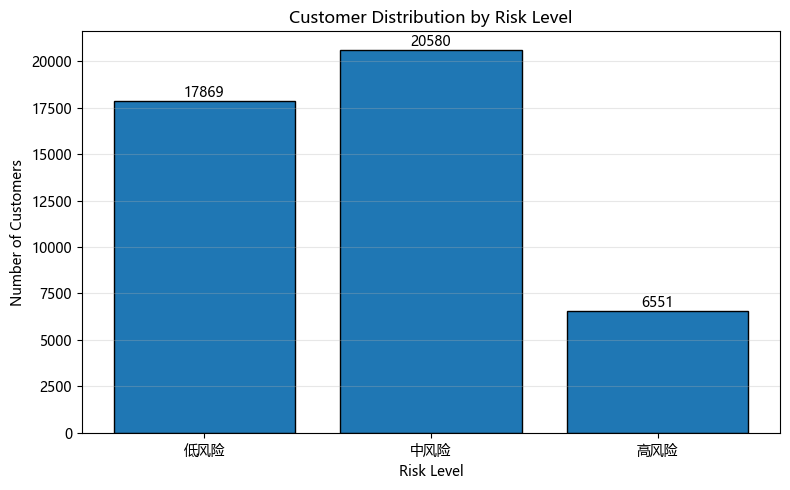

In [21]:

def classify_risk(probability):

    if probability < 0.02:
        return '低风险'

    elif probability < 0.10:
        return '中风险'

    else:
        return '高风险'

# 重新生成批量评分结果
batch_results = batch_score_customers(X_test)

# 添加风险等级
batch_results['风险等级'] = (
    batch_results['预测违约概率']
    .apply(classify_risk)
)

print("=== 客户批量评分结果 ===")
print(batch_results.head(20))

print("\n=== 各风险等级客户数量 ===")
print(batch_results['风险等级'].value_counts())

print("\n=== 各风险等级客户占比 ===")
print(
    batch_results['风险等级']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

risk_summary = batch_results.groupby('风险等级').agg(
    客户数量=('信用评分', 'count'),
    平均违约概率=('预测违约概率', 'mean'),
    平均信用评分=('信用评分', 'mean'),
    最低信用评分=('信用评分', 'min'),
    最高信用评分=('信用评分', 'max')
)

risk_summary['客户占比'] = (
    risk_summary['客户数量']
    / len(batch_results) * 100
).round(2)

print("=== 风险等级统计分析 ===")
print(risk_summary.round(4))


import matplotlib.pyplot as plt

# 设置中文字体
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']

# 解决负号显示异常
plt.rcParams['axes.unicode_minus'] = False


import matplotlib.pyplot as plt

risk_counts = batch_results['风险等级'].value_counts()

# 固定风险等级显示顺序
risk_order = ['低风险', '中风险', '高风险']
risk_counts = risk_counts.reindex(risk_order, fill_value=0)

plt.figure(figsize=(8, 5))

plt.bar(
    risk_counts.index,
    risk_counts.values,
    edgecolor='black'
)

plt.xlabel('Risk Level')
plt.ylabel('Number of Customers')
plt.title('Customer Distribution by Risk Level')

for i, value in enumerate(risk_counts.values):
    plt.text(i, value, str(value), ha='center', va='bottom')

plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


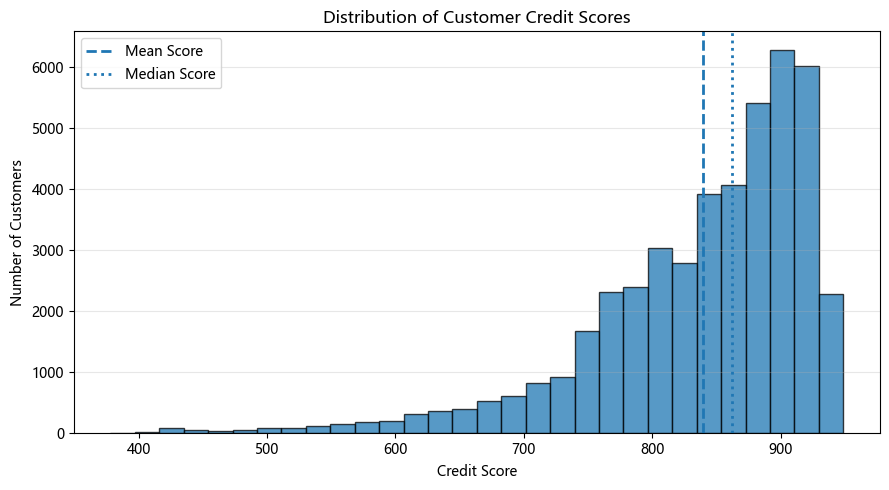

In [22]:

plt.figure(figsize=(9, 5))

plt.hist(
    batch_results['信用评分'],
    bins=30,
    edgecolor='black',
    alpha=0.75
)

plt.xlabel('Credit Score')
plt.ylabel('Number of Customers')
plt.title('Distribution of Customer Credit Scores')

plt.axvline(
    batch_results['信用评分'].mean(),
    linestyle='--',
    linewidth=2,
    label='Mean Score'
)

plt.axvline(
    batch_results['信用评分'].median(),
    linestyle=':',
    linewidth=2,
    label='Median Score'
)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


In [25]:

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)


# 选择新的分类阈值
best_threshold = 0.15

# 生成新的预测结果
y_pred_best = (y_pred_proba >= best_threshold).astype(int)

# 混淆矩阵
cm_best = confusion_matrix(y_test, y_pred_best)

print("=== 分类阈值：", best_threshold, "===")
print("\n=== 混淆矩阵 ===")
print(cm_best)

print("\n=== 分类评估指标 ===")
print("准确率：", round(accuracy_score(y_test, y_pred_best), 4))
print("精确率：", round(precision_score(y_test, y_pred_best), 4))
print("召回率：", round(recall_score(y_test, y_pred_best), 4))
print("F1值：", round(f1_score(y_test, y_pred_best), 4))

print("\n=== 分类报告 ===")
print(classification_report(
    y_test,
    y_pred_best,
    target_names=['正常客户', '违约客户']
))


=== 分类阈值： 0.15 ===

=== 混淆矩阵 ===
[[39395  2597]
 [ 1422  1586]]

=== 分类评估指标 ===
准确率： 0.9107
精确率： 0.3792
召回率： 0.5273
F1值： 0.4411

=== 分类报告 ===
              precision    recall  f1-score   support

        正常客户       0.97      0.94      0.95     41992
        违约客户       0.38      0.53      0.44      3008

    accuracy                           0.91     45000
   macro avg       0.67      0.73      0.70     45000
weighted avg       0.93      0.91      0.92     45000



In [28]:

# ==========================================
# 一、汇总模型评估指标
# ==========================================

from sklearn.metrics import (
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# 重新计算AUC，避免auc变量名称冲突
auc_value = roc_auc_score(y_test, y_pred_proba)

# 计算两种分类阈值下的预测结果
y_pred_05 = (y_pred_proba >= 0.5).astype(int)
y_pred_015 = (y_pred_proba >= 0.15).astype(int)

# 创建模型评估汇总表
model_evaluation = pd.DataFrame({
    '评估指标': [
        'AUC',
        'KS',
        '准确率（阈值0.5）',
        '精确率（阈值0.5）',
        '召回率（阈值0.5）',
        'F1值（阈值0.5）',
        '准确率（阈值0.15）',
        '精确率（阈值0.15）',
        '召回率（阈值0.15）',
        'F1值（阈值0.15）'
    ],
    '评估结果': [
        auc_value,
        ks,
        accuracy_score(y_test, y_pred_05),
        precision_score(y_test, y_pred_05, zero_division=0),
        recall_score(y_test, y_pred_05, zero_division=0),
        f1_score(y_test, y_pred_05, zero_division=0),
        accuracy_score(y_test, y_pred_015),
        precision_score(y_test, y_pred_015, zero_division=0),
        recall_score(y_test, y_pred_015, zero_division=0),
        f1_score(y_test, y_pred_015, zero_division=0)
    ]
})

print("=== 模型评估汇总表 ===")
print(model_evaluation.round(4).to_string(index=False))


# ==========================================
# 二、导出项目结果到Excel
# ==========================================

with pd.ExcelWriter('信用评分卡项目结果.xlsx') as writer:

    # 模型评估指标
    model_evaluation.to_excel(
        writer,
        sheet_name='模型评估',
        index=False
    )

    # 完整评分卡
    scorecard_full.to_excel(
        writer,
        sheet_name='完整评分卡',
        index=False
    )

    # 批量客户评分结果
    batch_results.to_excel(
        writer,
        sheet_name='客户评分结果',
        index=True
    )

    # 风险等级统计
    risk_summary.to_excel(
        writer,
        sheet_name='风险等级统计'
    )

    # 不同分类阈值的评估结果
    threshold_df.to_excel(
        writer,
        sheet_name='阈值分析',
        index=False
    )

print("\n项目结果已成功导出：信用评分卡项目结果.xlsx")


=== 模型评估汇总表 ===
       评估指标   评估结果
        AUC 0.8568
         KS 0.5617
 准确率（阈值0.5） 0.9373
 精确率（阈值0.5） 0.6011
 召回率（阈值0.5） 0.1828
 F1值（阈值0.5） 0.2804
准确率（阈值0.15） 0.9107
精确率（阈值0.15） 0.3792
召回率（阈值0.15） 0.5273
F1值（阈值0.15） 0.4411

项目结果已成功导出：信用评分卡项目结果.xlsx
